In [17]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils").is_dir())
UTILS = str(ROOT / "src" / "utils")
if UTILS not in sys.path:
    sys.path.insert(0, UTILS)

import polars as pl
from Move import Move
from chessboard import Chessboard
from pgn import open_pgn, read_games

PGN_PATH = "../../Data/lichess_db_standard_rated_2026-09.pgn.zst"
RAW_PATH = "../../Data/blitz_180_raw.parquet"

if not Path(RAW_PATH).exists():
    df = read_games(PGN_PATH, n_read=10_000, time_controls={"180+0", "180+2"})
    df.write_parquet(RAW_PATH)

df = pl.read_parquet(RAW_PATH)

df.head()

Event,Site,Date,Round,White,Black,Result,UTCDate,UTCTime,WhiteElo,BlackElo,WhiteRatingDiff,BlackRatingDiff,ECO,Opening,TimeControl,Termination,Movetext,WhiteTitle,BlackTitle,moves,n_moves
str,str,str,str,str,str,str,str,str,i32,i32,i32,i32,str,str,str,str,str,str,str,list[struct[3]],u32
"""Rated Blitz game""","""https://lichess.org/IMOSvErG""","""2026.09.01""","""-""","""DOMI60FR""","""Holizox""","""1/2-1/2""","""2026.09.01""","""00:00:20""",1735,1664,-2,2,"""D08""","""Queen's Gambit Declined: Albin…","""180+2""","""Normal""","""1. d4 { [%clk 0:03:00] } 1... …",null,null,"[{""d4"",""0:03:00"",null}, {""d5"",""0:03:00"",null}, … {""Kc4"",""0:01:28"",null}]",99
"""Rated Blitz game""","""https://lichess.org/bs18a5LO""","""2026.09.01""","""-""","""Q8KSA""","""IRS007""","""1-0""","""2026.09.01""","""00:00:22""",1991,2045,7,-7,"""C42""","""Petrov's Defense: Three Knight…","""180+0""","""Normal""","""1. e4 { [%clk 0:03:00] } 1... …",null,null,"[{""e4"",""0:03:00"",null}, {""e5"",""0:03:00"",null}, … {""Qe6+"",""0:00:27"",null}]",85
"""Rated Blitz game""","""https://lichess.org/YXYiz29z""","""2026.09.01""","""-""","""MiltonMorales""","""Glaidel""","""0-1""","""2026.09.01""","""00:00:23""",2224,2217,-6,6,"""B23""","""Sicilian Defense: Closed""","""180+0""","""Normal""","""1. e4 { [%clk 0:03:00] } 1... …",null,null,"[{""e4"",""0:03:00"",null}, {""c5"",""0:03:00"",null}, … {""Nf5"",""0:02:50"",null}]",28
"""Rated Blitz game""","""https://lichess.org/nnqUdpEC""","""2026.09.01""","""-""","""nallek""","""Botonems""","""1-0""","""2026.09.01""","""00:00:23""",1744,1649,4,-4,"""A00""","""Saragossa Opening""","""180+0""","""Time forfeit""","""1. c3 { [%clk 0:03:00] } 1... …",null,null,"[{""c3"",""0:03:00"",null}, {""e6"",""0:03:00"",null}, … {""Bd1"",""0:00:17"",null}]",65
"""Rated Blitz game""","""https://lichess.org/kXbkGSNm""","""2026.09.01""","""-""","""evgeniy_duk""","""Juanca_Master_Mind""","""0-1""","""2026.09.01""","""00:00:10""",1557,1611,-5,5,"""D40""","""Queen's Gambit Declined: Semi-…","""180+2""","""Normal""","""1. d4 { [%clk 0:03:00] } 1... …",null,null,"[{""d4"",""0:03:00"",null}, {""d5"",""0:03:00"",null}, … {""Rxh4#"",""0:00:43"",null}]",70


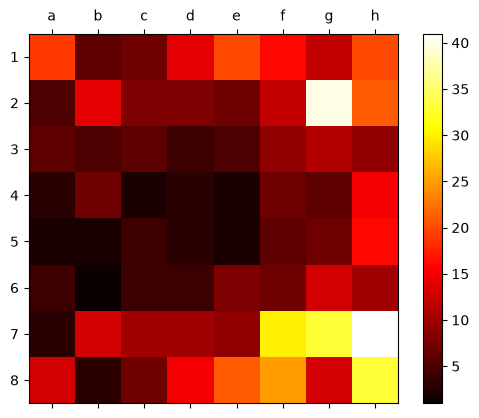

In [17]:

all_games = Chessboard()
for moves in df["moves"]:
    for move in moves:
        c_move = Move.parse(move["san"])
        if c_move.checkmate:
            all_games.count_positions([c_move])
all_games.draw_heatmap()